In [ ]:
import cv2
from pathlib import Path

video_path = Path.cwd().resolve() / "data" / "videos" / "v_BabyCrawling_g19_c02.avi"
# Path.cwd() gets your current working directory.
# .resolve() converts it into an absolute path.

cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise RuntimeError("Could'nt open video: {video_path}")

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration = frame_count/fps if fps>0 else 0

print(f"Video: {video_path.name}")
print(f"Resolution: {width}*{height}")
print(f"FPS: {fps:.2f}")
print(f"Frames: {frame_count}")
print(f"duration: {duration:.2f} seconds")

ret,frame = cap.read()
if ret:
    output_path = video_path.parent.parent/"first_frame.jpg"
    cv2.imwrite(str(output_path), frame)
    print(f"First frame saved to: {output_path}")

cap.release()

Video: v_BabyCrawling_g19_c02.avi
Resolution: 320*240
FPS: 25.00
Frames: 170
duration: 6.80 seconds
First frame saved to: C:\Users\HP\OneDrive\Desktop\DL-Pytorch\PHYSICA\data\first_frame.jpg


In [7]:
%pip install ultralytics
from ultralytics import YOLO

model = YOLO("yolo11n.pt")
print("YOLO model loaded successfully!")

Note: you may need to restart the kernel to use updated packages.
YOLO model loaded successfully!


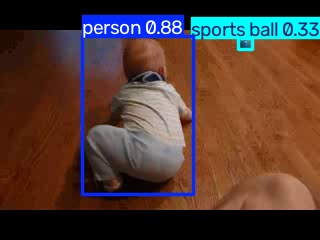

In [3]:
import cv2 
from pathlib import Path
from IPython.display import display, Image

video_path = Path.cwd() / "data" / "videos" / "v_BabyCrawling_g19_c02.avi"

cap = cv2.VideoCapture(str(video_path))
ret,frame = cap.read()
cap.release()

if not ret:
    raise RuntimeError(f"Could'nt read video {video_path}")

results = model.predict(frame , device="cpu" , verbose = False)
annotated_frame = results[0].plot()

output_path = Path.cwd() / "outputs"/"annotated" / "first_frame.jpg"
output_path.parent.mkdir(parents = True , exist_ok = True)

cv2.imwrite(str(output_path), annotated_frame)
display(Image(filename = str(output_path)))

In [ ]:
import cv2 
import pandas as pd
from pathlib import Path

# paths
video = Path.cwd().resolve() / "data" / "videos" / "v_BabyCrawling_g19_c02.avi"
out = Path.cwd().resolve() / "outputs"
(out/"annotated").mkdir(parents = True , exist_ok = True)
(out/"detections").mkdir(parents = True , exist_ok = True)

# open video
cap = cv2.VideoCapture(str(video))
if not cap.isOpened():
    raise RuntimeError(f"Could'nt open video {video}")

fps = cap.get(cv2.CAP_PROP_FPS)
rows = []           # Stores information about detected objects written below
frame_id = 0

# Process every 5th frame
while True:
    ret, frame = cap.read()
    if not ret:
        break

    if frame_id % 5 == 0:
        result = model.predict(frame ,              # frame is the current image.
                               device = "cpu" ,
                               verbose = False)[0]          #suppresses detailed prediction logs.

        for box in result.boxes:
            x1,y1,x2,y2 = box.xyxy[0].tolist()
            cls = int(box.cls[0])       #numerical class ID predicted by the model.
            conf = float(box.conf[0])

            rows.append({
                "timestamp": round(frame_id / fps , 2) if fps>0 else 0 ,
                "frame": frame_id,
                "object": model.names[cls],     # converts a numerical class ID into its label, such as "person"
                "confidence": round(conf,3),
                "x1": round(x1, 1),     # x1,y1 are for objects in top left corner that is used to find length of box
                "y1": round(y1, 1),
                "x2": round(x2, 1),     # x2,y2 for objects in bottom right corner that is used to find width of box
                "y2": round(y2, 1)
            })

        result.save(out / "annotated" / f"frame_{frame_id:06d}.jpg")        #creates a zero-padded filename.
    frame_id += 1   # frame_id += 1 increases the counter by one for each frame read.
                    #Indentation matters here: frame_id += 1 must be inside the while loop, but cap.release() must be outside it. Otherwise, the video would be released after the first iteration.
cap.release()

df = pd.DataFrame(rows)
df.to_csv(out / "detections" / "detections.csv", index=False)

print(f"Frames read: {frame_id}")
print(f"Object detected: {len(df)}")
print(f"Unique Object detected: {df['object'].nunique() if not df.empty else 0}")
print("csv saved:", out / "detections" / "detections.csv")
print("Annotated frames saved:", out/"annotated")
display(df.head(10))     

Frames read: 170
Object detected: 64
Unique Object detected: 9
csv saved: C:\Users\HP\OneDrive\Desktop\DL-Pytorch\PHYSICA\outputs\detections\detections.csv
Annotated frames saved: C:\Users\HP\OneDrive\Desktop\DL-Pytorch\PHYSICA\outputs\annotated


,timestamp,frame,object,confidence,x1,y1,x2,y2
0,0.0,0,person,0.877,82.7,36.5,193.9,194.6
1,0.0,0,sports ball,0.332,238.3,38.8,252.4,49.4
2,0.2,5,person,0.854,68.1,35.5,202.2,200.8
3,0.2,5,sports ball,0.276,240.9,45.3,255.3,56.4
4,0.4,10,person,0.816,52.4,36.9,202.8,197.3
5,0.6,15,person,0.836,55.3,42.1,200.8,190.4
6,0.6,15,sports ball,0.284,237.0,58.5,252.8,69.4
7,0.8,20,person,0.886,50.8,49.7,195.3,206.8
8,1.0,25,person,0.831,56.7,58.0,192.1,209.5
9,1.2,30,person,0.757,61.4,59.7,185.1,200.6


In [ ]:
from pathlib import Path
import pandas as pd

out = Path.cwd() / "outputs"

# Check saved files
print("Annotated frames:", len(list((out / "annotated").glob("*.jpg"))))

csv_path = out / "detections" / "detections.csv"
df = pd.read_csv(csv_path)

print("Total detections:", len(df))
print("Object classes:", df["object"].unique())
display(df.head())

Annotated frames: 35
Total detections: 64
Object classes: ['person' 'sports ball' 'tv' 'donut' 'laptop' 'dog' 'book' 'mouse' 'cat']


,timestamp,frame,object,confidence,x1,y1,x2,y2
0,0.0,0,person,0.877,82.7,36.5,193.9,194.6
1,0.0,0,sports ball,0.332,238.3,38.8,252.4,49.4
2,0.2,5,person,0.854,68.1,35.5,202.2,200.8
3,0.2,5,sports ball,0.276,240.9,45.3,255.3,56.4
4,0.4,10,person,0.816,52.4,36.9,202.8,197.3


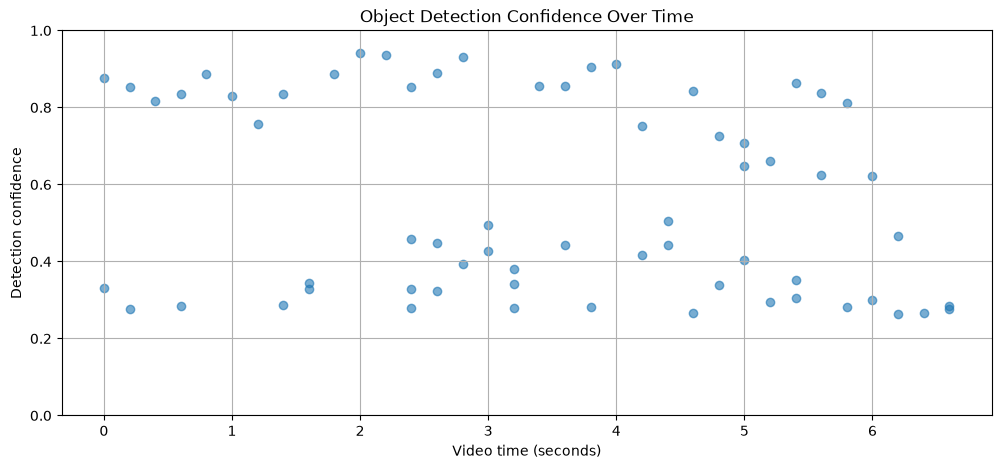

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

csv_path = Path.cwd().resolve() / "outputs" / "detections" / "detections.csv"
df = pd.read_csv(csv_path)

if df.empty:
    print(f"No object in the video")
else:
    plt.figure(figsize=(12,5))

    plt.scatter(df["timestamp"] , df["confidence"] , alpha=0.6)

    plt.xlabel("Video time (seconds)")
    plt.ylabel("Detection confidence")
    plt.title("Object Detection Confidence Over Time")
    plt.ylim(0, 1)
    plt.grid(True)
    plt.show()

object
person         25
sports ball    10
mouse          10
dog             9
cat             4
donut           2
book            2
laptop          1
tv              1
Name: count, dtype: int64


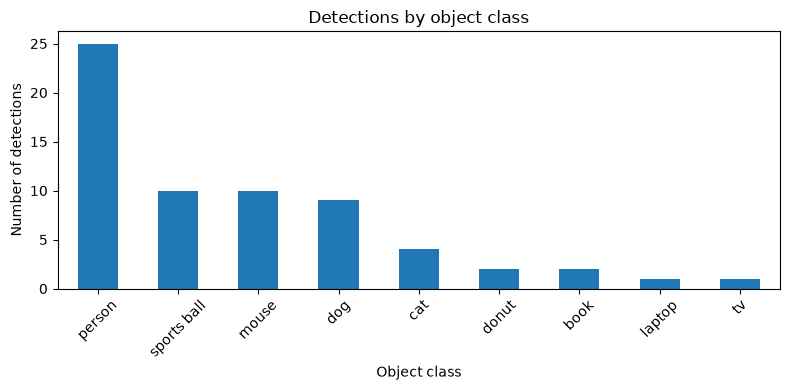

In [12]:
class_counts = df["object"].value_counts()
print(class_counts)

class_counts.plot(
    kind = "bar",
    figsize = (8,4),
    title = "Detections by object class"
)

plt.xlabel("Object class")
plt.ylabel("Number of detections")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
from ultralytics import YOLO
from pathlib import Path

video = Path.cwd().resolve() / "data" / "videos" / "v_BabyCrawling_g19_c02.avi"
out = Path.cwd().resolve() / "outputs"
out.mkdir(exist_ok = True)

model = YOLO("yolo11n.pt")

results = model.track(
    source = str(video),
    persist = True,
    tracker = "bytetrack.yaml",
    save = True,
    project = str(out),
    name = "Tracking",
    exist_ok = True,
    device = "cpu"
)

print("Tracking Finished!")

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ----------------------------------- ---- 1.3/1.5 MB 9.6 MB/s eta 0:00:01
   ---------------------------------------- 1.5/1.5 MB 9.7 MB/s  0:00:00

requirements: AutoUpdate success  5.2s
WARNING requirements: Restart runtime or rerun command for updates to take effect


WARNING 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/170) C:\User

In [15]:
# Code below reprocesses the video for tracking and writes the tracking data to a CSV.

import cv2
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

video = Path.cwd().resolve() / "data" / "videos" / "v_BabyCrawling_g19_c02.avi"
out = Path.cwd().resolve() / "outputs"
csv_dir = out/"detections"
csv_dir.mkdir(parents = True , exist_ok = True)

model = YOLO("yolo11n.pt")

cap = cv2.VideoCapture(str(video))
if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {video}")

fps = cap.get(cv2.CAP_PROP_FPS)
rows = []
frame_id = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    result = model.track(
        frame,
        persist = True,
        tracker = "bytetrack.yaml",
        device = "cpu",
        verbose = False
    )[0]

    if result.boxes is not None and result.boxes.id is not None:
        boxes = result.boxes
        track_ids = boxes.id.int().cpu().tolist()
        classes = boxes.cls.int().cpu().tolist()
        confidences = boxes.conf.cpu().tolist()
        coordinates = boxes.xyxy.cpu().tolist()

        for track_id,cls,conf,xyxy in zip(
            track_ids , classes, confidences, coordinates
        ):
            x1,y1,x2,y2 = xyxy

            rows.append({
                "frame": frame_id,
                "timestamp": round(frame_id/fps , 2) if fps>0 else 0,
                "track_id": track_id,
                "object": model.names[cls],
                "confidence": round(conf,3),
                "x1": round(x1,1),
                "y1": round(y1,1),
                "x2": round(x2,1),
                "y2": round(y2,1)
            })
    frame_id += 1
cap.release()

df_tracks = pd.DataFrame(rows)
csv_path = csv_dir / "tracking.csv"
df_tracks.to_csv(csv_path, index=False)

print("Frames processed:", frame_id)
print("Tracking records:", len(df_tracks))
print("Unique track ids:", df_tracks["track_id"].nunique() if not df_tracks.empty else 0)
print("Saved to:", csv_path)

display(df_tracks.head(10))

Frames processed: 170
Tracking records: 351
Unique track ids: 12
Saved to: C:\Users\HP\OneDrive\Desktop\DL-Pytorch\PHYSICA\outputs\detections\tracking.csv


,frame,timestamp,track_id,object,confidence,x1,y1,x2,y2
0,0,0.00,1,person,0.877,82.7,36.5,193.9,194.6
1,0,0.00,2,sports ball,0.332,238.3,38.8,252.4,49.4
2,1,0.04,1,person,0.837,81.0,35.9,195.5,198.8
3,1,0.04,2,sports ball,0.240,238.0,39.1,252.4,50.0
4,2,0.08,1,person,0.890,82.7,36.9,196.7,199.1
5,2,0.08,2,sports ball,0.183,238.2,39.8,253.1,51.2
6,3,0.12,1,person,0.904,82.6,37.3,198.3,201.7
7,3,0.12,2,sports ball,0.458,239.0,41.1,253.7,52.2
8,4,0.16,1,person,0.886,78.2,36.3,194.4,200.1
9,4,0.16,2,sports ball,0.247,240.2,42.8,254.4,53.6


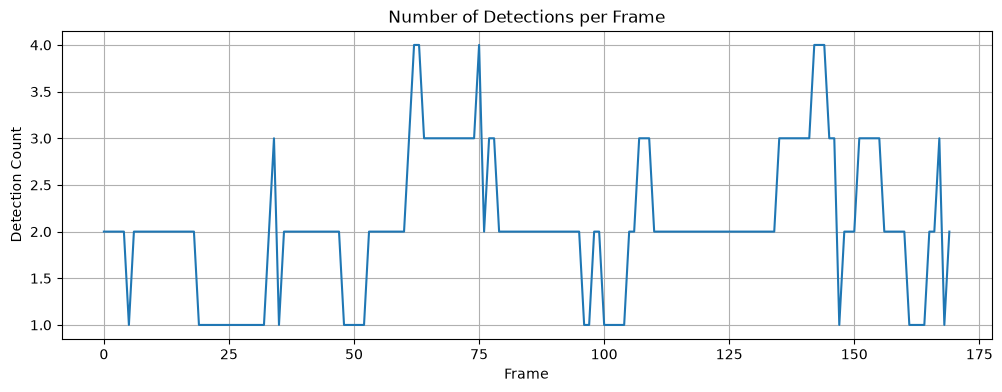

In [16]:
import matplotlib.pyplot as plt

detections_per_frame = df_tracks.groupby("frame").size()

plt.figure(figsize=(12, 4))
detections_per_frame.plot()
plt.title("Number of Detections per Frame")
plt.xlabel("Frame")
plt.ylabel("Detection Count")
plt.grid(True)
plt.show()

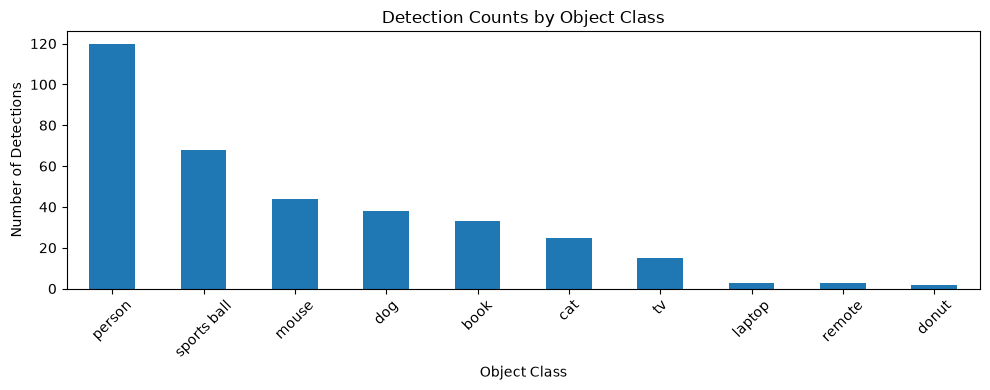

In [17]:
# 2. Detection counts by object class
plt.figure(figsize=(10, 4))
df_tracks["object"].value_counts().plot(kind="bar")
plt.title("Detection Counts by Object Class")
plt.xlabel("Object Class")
plt.ylabel("Number of Detections")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

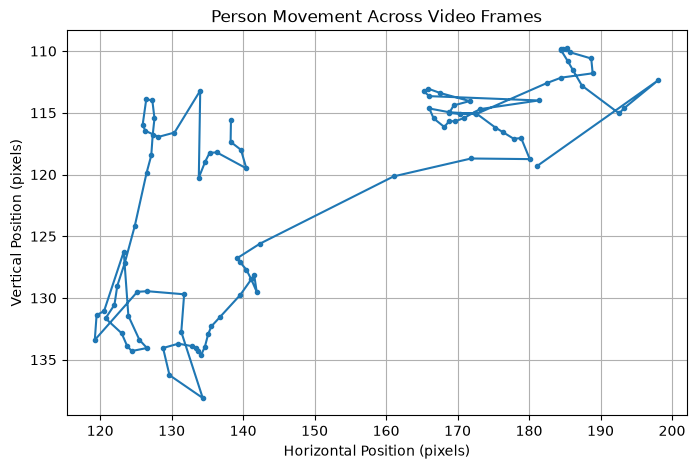

Person detections: 101


In [ ]:
# Analyze object movement across frames.
import matplotlib.pyplot as plt

df_tracks["center_x"] = (df_tracks["x1"] + df_tracks["x2"]) / 2
df_tracks["center_y"] = (df_tracks["y1"] + df_tracks["y2"]) / 2

# Select the person with track ID 1
person = df_tracks[(df_tracks["track_id"] == 1) & (df_tracks["object"] == "person")].sort_values("frame")

plt.figure(figsize = (8,5))
plt.plot(person["center_x"], person["center_y"], marker='o', markersize = 3)
plt.title("Person Movement Across Video Frames")
plt.xlabel("Horizontal Position (pixels)")
plt.ylabel("Vertical Position (pixels)")
plt.gca().invert_yaxis()
plt.grid(True)
plt.show()

print("Person detections:" , len(person))

# how bounding boxes become coordinates that can be used to analyze movement.
# The plot shows image-plane movement, not actual physical distance.

In [20]:
track_summary = df_tracks.groupby(["track_id" , "object"]).agg(
    first_frame = ("frame","min"),
    last_frame = ("frame","max"),
    detection_count = ("frame" , "count"),
    mean_confidence = ("confidence" , "mean")
).reset_index()

track_summary["duration_seconds"] = (track_summary["last_frame"] - track_summary["first_frame"]) / fps if fps>0 else 0

track_summary = track_summary.sort_values(
    "detection_count", ascending = False
)

In [21]:
print("========== TRACKING REPORT ==========")
print("Video frames processed:", frame_id)
print("total detection records:", len(df_tracks))
print("Unique track IDS:", df_tracks["track_id"].nunique())
print("object classes detected:", df_tracks["object"].nunique())
print("Missing values:", df_tracks.isnull().sum().sum())

print("\nDetection counts by class:")
print(df_tracks["object"].value_counts())

report_path = out / "tracking_report.txt"

with open(report_path, "w", encoding="utf-8") as f:
    f.write("Tracking Report\n")
    f.write(f"Video frames processed: {frame_id}\n")
    f.write(f"Detection records: {len(df_tracks)}\n")
    f.write(f"Unique track IDs: {df_tracks['track_id'].nunique()}\n")
    f.write(f"Object classes detected: {df_tracks['object'].nunique()}\n")
    f.write(f"Missing values: {df_tracks.isnull().sum().sum()}\n\n")
    f.write("Detection counts by class:\n")
    f.write(df_tracks["object"].value_counts().to_string())

print("\n Report saved to:", report_path)

========== TRACKING REPORT ==========
Video frames processed: 170
total detection records: 351
Unique track IDS: 12
object classes detected: 10
Missing values: 0

Detection counts by class:
object
person         120
sports ball     68
mouse           44
dog             38
book            33
cat             25
tv              15
laptop           3
remote           3
donut            2
Name: count, dtype: int64

 Report saved to: C:\Users\HP\OneDrive\Desktop\DL-Pytorch\PHYSICA\outputs\tracking_report.txt


In [31]:
import cv2
from pathlib import Path
from IPython.display import Video, display

source = Path(r"C:\Users\HP\OneDrive\Desktop\DL-Pytorch\PHYSICA\outputs\Tracking\v_BabyCrawling_g19_c02.avi")
output = source.with_name("tracking_preview.mp4")

cap = cv2.VideoCapture(str(source))

if not cap.isOpened():
    print("Could not read the AVI file.")
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    writer = cv2.VideoWriter(
        str(output),
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps if fps > 0 else 25,
        (width, height)
    )

    count = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        writer.write(frame)
        count += 1

    cap.release()
    writer.release()

    print("Frames converted:", count)
    print("MP4 saved:", output)


Frames converted: 170
MP4 saved: C:\Users\HP\OneDrive\Desktop\DL-Pytorch\PHYSICA\outputs\Tracking\tracking_preview.mp4


In [30]:
import imageio_ffmpeg
import subprocess
from pathlib import Path
from IPython.display import Video, display

source = Path(r"C:\Users\HP\OneDrive\Desktop\DL-Pytorch\PHYSICA\outputs\Tracking\v_BabyCrawling_g19_c02.avi")
output = source.with_name("tracking_preview_h264.mp4")

ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()

result = subprocess.run([
    ffmpeg, "-y",
    "-i", str(source),
    "-c:v", "libx264",
    "-pix_fmt", "yuv420p",
    "-movflags", "+faststart",
    "-an", str(output)
], capture_output=True, text=True)

if result.returncode == 0 and output.exists():
    print("H.264 conversion successful:", output)
    display(Video(str(output), embed=True, width=800))
else:
    print("Conversion failed:")
    print(result.stderr[-3000:])

H.264 conversion successful: C:\Users\HP\OneDrive\Desktop\DL-Pytorch\PHYSICA\outputs\Tracking\tracking_preview_h264.mp4


In [29]:
%pip install imageio-ffmpeg

   ---------------------------------------- 0.0/31.2 MB ? eta -:--:--
   - -------------------------------------- 0.8/31.2 MB 8.5 MB/s eta 0:00:04
   --- ------------------------------------ 2.9/31.2 MB 9.3 MB/s eta 0:00:04
   ------ --------------------------------- 5.0/31.2 MB 9.4 MB/s eta 0:00:03
   -------- ------------------------------- 6.3/31.2 MB 8.6 MB/s eta 0:00:03
   --------- ------------------------------ 7.1/31.2 MB 7.3 MB/s eta 0:00:04
   ---------- ----------------------------- 8.1/31.2 MB 6.9 MB/s eta 0:00:04
   ----------- ---------------------------- 9.2/31.2 MB 6.6 MB/s eta 0:00:04
   ------------ --------------------------- 9.4/31.2 MB 6.3 MB/s eta 0:00:04
   ------------ --------------------------- 9.7/31.2 MB 5.5 MB/s eta 0:00:04
   ------------ --------------------------- 10.0/31.2 MB 5.0 MB/s eta 0:00:05
   ------------- -------------------------- 10.5/31.2 MB 4.8 MB/s eta 0:00:05
   ------------- -------------------------- 10.7/31.2 MB 4.7 MB/s eta 0:00:05
   

In [32]:
from pathlib import Path
import pandas as pd

csv_path = Path.cwd() / "outputs" / "detections" / "tracking.csv"

if csv_path.exists():
    tracking_df = pd.read_csv(csv_path)

    print("Dataset shape:", tracking_df.shape)
    print("\nColumns:")
    print(tracking_df.columns.tolist())

    print("\nFirst 10 records:")
    display(tracking_df.head(10))

    print("\nMissing values:")
    display(tracking_df.isnull().sum())
else:
    print("Tracking CSV not found at:", csv_path)
    print("Current notebook directory:", Path.cwd())


Dataset shape: (351, 9)

Columns:
['frame', 'timestamp', 'track_id', 'object', 'confidence', 'x1', 'y1', 'x2', 'y2']

First 10 records:


,frame,timestamp,track_id,object,confidence,x1,y1,x2,y2
0,0,0.00,1,person,0.877,82.7,36.5,193.9,194.6
1,0,0.00,2,sports ball,0.332,238.3,38.8,252.4,49.4
2,1,0.04,1,person,0.837,81.0,35.9,195.5,198.8
3,1,0.04,2,sports ball,0.240,238.0,39.1,252.4,50.0
4,2,0.08,1,person,0.890,82.7,36.9,196.7,199.1
5,2,0.08,2,sports ball,0.183,238.2,39.8,253.1,51.2
6,3,0.12,1,person,0.904,82.6,37.3,198.3,201.7
7,3,0.12,2,sports ball,0.458,239.0,41.1,253.7,52.2
8,4,0.16,1,person,0.886,78.2,36.3,194.4,200.1
9,4,0.16,2,sports ball,0.247,240.2,42.8,254.4,53.6



Missing values:


frame         0
timestamp     0
track_id      0
object        0
confidence    0
x1            0
y1            0
x2            0
y2            0
dtype: int64

Unique tracked objects: 12
Total tracking records: 351


,frame,track_id,object,center_x,center_y,movement_pixels
0,0,1,person,138.30,115.55,NaN
2,1,1,person,138.25,117.35,1.800694
4,2,1,person,139.70,118.00,1.589025
6,3,1,person,140.45,119.50,1.677051
8,4,1,person,136.30,118.20,4.348850
10,5,1,person,135.30,118.25,1.001249
11,6,1,person,134.70,118.95,0.921954
13,7,1,person,133.80,120.25,1.581139
15,8,1,person,134.00,113.20,7.052836
17,9,1,person,130.40,116.60,4.951767


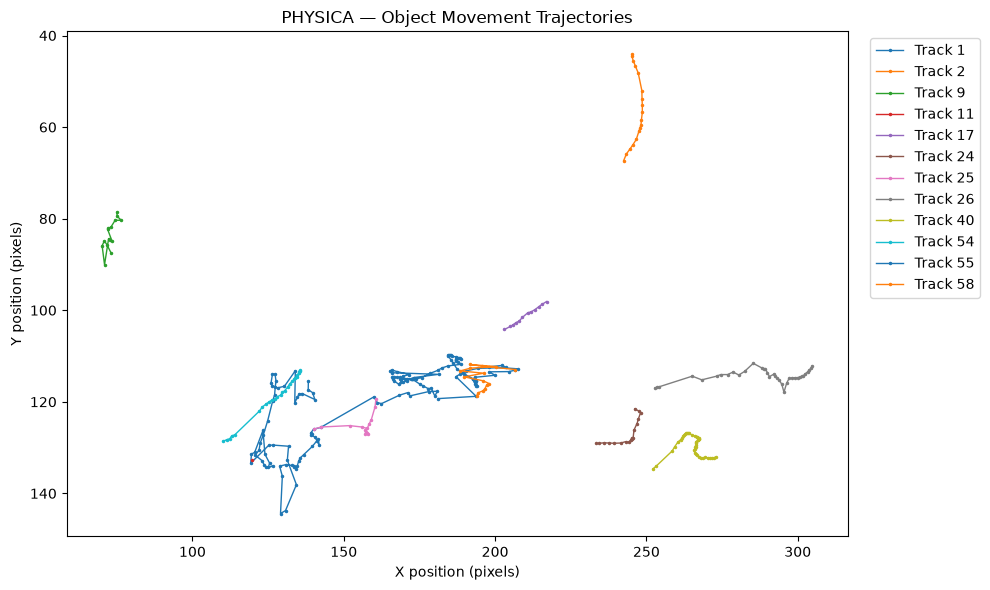

In [33]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Load tracking data
csv_path = Path.cwd() / "outputs" / "detections" / "tracking.csv"
df = pd.read_csv(csv_path)

# Calculate the center of each bounding box
df["center_x"] = (df["x1"] + df["x2"]) / 2
df["center_y"] = (df["y1"] + df["y2"]) / 2

# Sort observations in chronological order
df = df.sort_values(["track_id", "frame"])

# Calculate movement between consecutive observations
df["dx"] = df.groupby("track_id")["center_x"].diff()
df["dy"] = df.groupby("track_id")["center_y"].diff()

# Pixel displacement between observations
df["movement_pixels"] = (df["dx"]**2 + df["dy"]**2)**0.5

print("Unique tracked objects:", df["track_id"].nunique())
print("Total tracking records:", len(df))
display(df[["frame", "track_id", "object",
            "center_x", "center_y", "movement_pixels"]].head(10))

# Plot the trajectory of each tracked object
plt.figure(figsize=(10, 6))

for track_id, group in df.groupby("track_id"):
    plt.plot(
        group["center_x"],
        group["center_y"],
        marker=".",
        markersize=3,
        linewidth=1,
        label=f"Track {track_id}"
    )

plt.gca().invert_yaxis()
plt.xlabel("X position (pixels)")
plt.ylabel("Y position (pixels)")
plt.title("PHYSICA — Object Movement Trajectories")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [34]:
import pandas as pd

movement_summary = (df.groupby(["track_id","object"]).agg(
    first_frame = ("frame","min"),
    last_frame = ("frame","max"),
    observations = ("frame" , "count"),
    total_displacement_pixels = ("movement_pixels" , "sum"),
    average_step_pixels = ("movement_pixels" , "mean"),
    maximum_step_pixels = ("movement_pixels" , "max")
).reset_index())

movement_summary["duration_frames"] = (
    movement_summary["last_frame"] - movement_summary["first_frame"] + 1
)

movement_summary = movement_summary.sort_values("total_displacement_pixels" , ascending = False)

display(movement_summary.round(2))

output_path = Path.cwd().resolve() / "outputs" / "detections" / "movement_summary.csv"
output_path.parent.mkdir(parents=True , exist_ok = True)
movement_summary.to_csv(output_path , index=False)

print("\nSaved movement summary to:", output_path)

,track_id,object,first_frame,last_frame,observations,total_displacement_pixels,average_step_pixels,maximum_step_pixels,duration_frames
2,1,person,0,169,101,234.36,2.34,15.30,170
1,1,dog,28,167,32,75.54,2.36,18.88,140
13,26,book,67,109,33,57.55,1.74,11.09,43
0,1,cat,41,159,15,49.21,3.28,9.30,119
23,58,dog,154,165,5,31.37,6.27,11.03,12
18,54,sports ball,135,169,25,29.89,1.25,9.67,35
22,58,cat,153,164,7,28.67,4.78,8.71,12
15,40,mouse,105,152,42,28.01,0.68,6.31,48
4,9,tv,33,47,15,26.85,1.92,5.86,15
12,25,person,62,75,13,26.58,2.21,9.35,14



Saved movement summary to: C:\Users\HP\OneDrive\Desktop\DL-Pytorch\PHYSICA\outputs\detections\movement_summary.csv


In [35]:
import pandas as pd
from pathlib import Path

valid_movement = df["movement_pixels"].dropna()
threshold = valid_movement.quantile(0.95)

df["large_movement"] = df["movement_pixels"] > threshold

candidate_events = df[df["large_movement"]].copy()

print(f"95th percentile movement threshold: {threshold:.2f} pixels")
print("Candidate movement jumps:", len(candidate_events))

display(
    candidate_events[
        ["frame", "timestamp", "track_id", "object",
         "movement_pixels", "center_x", "center_y"]
    ].sort_values("movement_pixels", ascending=False).head(20)
)

# Save candidate events
events_path = Path.cwd() / "outputs" / "detections" / "candidate_events.csv"
events_path.parent.mkdir(parents=True, exist_ok=True)
candidate_events.to_csv(events_path, index=False)

print("\nSaved candidate events to:", events_path)

95th percentile movement threshold: 6.79 pixels
Candidate movement jumps: 17


,frame,timestamp,track_id,object,movement_pixels,center_x,center_y
149,75,3.00,1,dog,18.878890,160.00,118.90
194,98,3.92,1,person,15.304003,181.35,114.00
350,169,6.76,1,person,12.609917,181.15,119.30
209,107,4.28,26,book,11.091100,254.30,116.70
323,154,6.16,58,dog,11.025539,195.70,112.20
342,165,6.60,54,sports ball,9.667601,114.00,127.20
322,154,6.16,1,person,9.560596,198.10,112.35
115,64,2.56,25,person,9.354812,151.95,125.20
329,157,6.28,1,cat,9.302150,194.35,112.70
328,156,6.24,58,cat,8.711630,200.25,112.30



Saved candidate events to: c:\Users\HP\OneDrive\Desktop\DL-Pytorch\PHYSICA\outputs\detections\candidate_events.csv


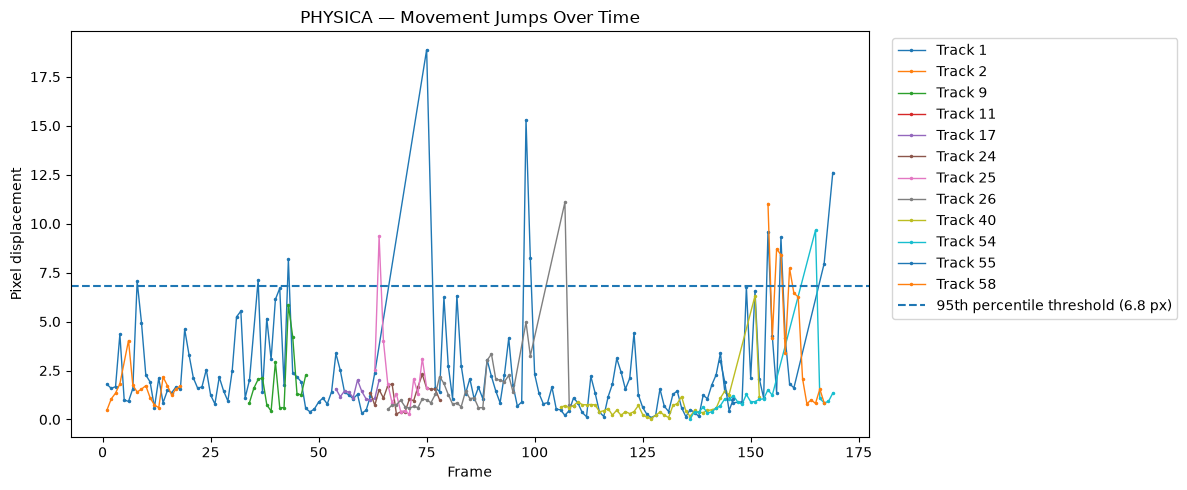

In [ ]:
import matplotlib.pyplot as plt

# Plot movement for each tracked object
plt.figure(figsize=(12, 5))

for track_id, group in df.groupby("track_id"):
    group = group.sort_values("frame")
    plt.plot(
        group["frame"],
        group["movement_pixels"],
        marker=".",
        markersize=3,
        linewidth=1,
        label=f"Track {track_id}"
    )

plt.axhline(
    threshold,
    linestyle="--",
    label=f"95th percentile threshold ({threshold:.1f} px)"
)

plt.xlabel("Frame")
plt.ylabel("Pixel displacement")
plt.title("PHYSICA — Movement Jumps Over Time")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Small, steady values: relatively smooth tracked movement.
# Sharp spikes: possible sudden motion, a tracking ID switch, or a detection jump.
# Repeated spikes: could indicate a recurring tracking problem—or genuine rapid movement.

In [37]:
import pandas as pd
from pathlib import Path

# Define a test region in pixel coordinates.
# Adjust these values later to match your video.

REGION = {
    "x_min": 200,
    "y_min": 100,
    "x_max": 500,
    "y_max": 400
}

df = df.sort_values(["track_id", "frame"]).copy()

df["inside_region"] = df["center_x"].between(REGION["x_min"],REGION["x_max"]) & df["center_y"].between(REGION["y_min"],REGION["y_max"])

print("Region:" , REGION)
print("Observation inside region", int(df["inside_region"].sum()))
print("Total observations:", len(df))

Region: {'x_min': 200, 'y_min': 100, 'x_max': 500, 'y_max': 400}
Observation inside region 113
Total observations: 351


In [38]:
events = []

for track_id, group in df.groupby("track_id", sort=False):
    group = group.sort_values("frame")
    previous_state = None

    for _, row in group.iterrows():
        current_state = bool(row["inside_region"])

        if previous_state is not None and current_state != previous_state:
            event_type = "ENTER" if current_state else "EXIT"

            events.append({
                "frame": int(row["frame"]),
                "timestamp": row["timestamp"],
                "track_id": track_id,
                "object": row["object"],
                "event": event_type,
                "center_x": row["center_x"],
                "center_y": row["center_y"]
            })

        previous_state = current_state

events_df = pd.DataFrame(
    events,
    columns=[
        "frame", "timestamp", "track_id", "object",
        "event", "center_x", "center_y"
    ]
)

display(events_df.head(20))
print("Entry/exit transitions detected:", len(events_df))


,frame,timestamp,track_id,object,event,center_x,center_y
0,149,5.96,1,cat,ENTER,200.00,114.20
1,150,6.00,1,cat,EXIT,198.00,113.45
2,151,6.04,1,cat,ENTER,204.55,113.40
3,154,6.16,1,person,EXIT,198.10,112.35
4,155,6.20,1,dog,ENTER,202.35,112.05
5,157,6.28,1,cat,EXIT,194.35,112.70
6,57,2.28,17,sports ball,ENTER,211.90,100.35
7,154,6.16,58,dog,EXIT,195.70,112.20
8,156,6.24,58,cat,ENTER,200.25,112.30
9,157,6.28,58,dog,EXIT,191.85,112.65


Entry/exit transitions detected: 10


In [39]:
output_path = (
    Path.cwd() / "outputs" / "detections" / "region_events.csv"
)
output_path.parent.mkdir(parents=True, exist_ok=True)
events_df.to_csv(output_path, index=False)

print("Saved:", output_path)
print("\nEvent counts:")
print(events_df["event"].value_counts() if not events_df.empty
      else "No entry/exit transitions detected.")


Saved: c:\Users\HP\OneDrive\Desktop\DL-Pytorch\PHYSICA\outputs\detections\region_events.csv

Event counts:
event
ENTER    5
EXIT     5
Name: count, dtype: int64


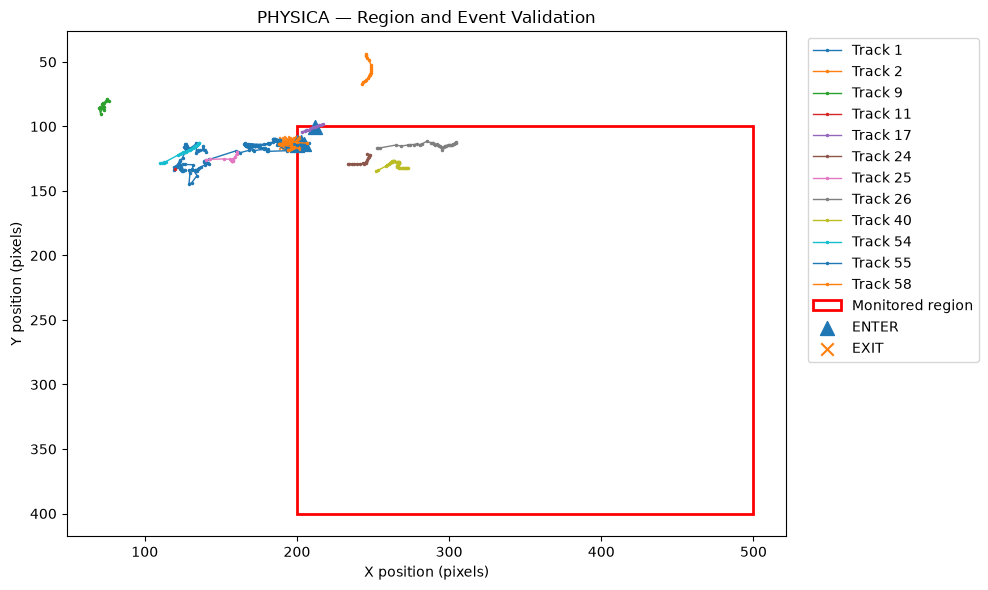

In [40]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.figure(figsize=(10, 6))

# Plot each tracked object's trajectory
for track_id, group in df.groupby("track_id"):
    group = group.sort_values("frame")
    plt.plot(
        group["center_x"],
        group["center_y"],
        marker=".",
        markersize=3,
        linewidth=1,
        label=f"Track {track_id}"
    )

# Draw the monitored region
region_box = Rectangle(
    (REGION["x_min"], REGION["y_min"]),
    REGION["x_max"] - REGION["x_min"],
    REGION["y_max"] - REGION["y_min"],
    fill=False,
    edgecolor="red",
    linewidth=2,
    label="Monitored region"
)

plt.gca().add_patch(region_box)

# Mark detected entries and exits
if not events_df.empty:
    entries = events_df[events_df["event"] == "ENTER"]
    exits = events_df[events_df["event"] == "EXIT"]

    plt.scatter(
        entries["center_x"], entries["center_y"],
        marker="^", s=100, label="ENTER"
    )
    plt.scatter(
        exits["center_x"], exits["center_y"],
        marker="x", s=80, label="EXIT"
    )

plt.gca().invert_yaxis()
plt.xlabel("X position (pixels)")
plt.ylabel("Y position (pixels)")
plt.title("PHYSICA — Region and Event Validation")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [41]:
import pandas as pd
from pathlib import Path

# Sort all events chronologically
event_timeline = events_df.sort_values(
    ["frame", "track_id"]
).reset_index(drop=True)

# Add a readable event description
if not event_timeline.empty:
    event_timeline["description"] = event_timeline.apply(
        lambda row: (
            f"Track {row['track_id']} ({row['object']}) "
            f"{'entered' if row['event'] == 'ENTER' else 'exited'} "
            f"the region at frame {row['frame']}"
        ),
        axis=1
    )
else:
    event_timeline["description"] = pd.Series(dtype=str)

display(event_timeline[
    ["frame", "timestamp", "track_id", "object", "event", "description"]
])

# Save the reconstructed timeline
timeline_path = (
    Path.cwd() / "outputs" / "detections" / "event_timeline.csv"
)
timeline_path.parent.mkdir(parents=True, exist_ok=True)
event_timeline.to_csv(timeline_path, index=False)

print("\nEvents in timeline:", len(event_timeline))
print("Saved to:", timeline_path)

,frame,timestamp,track_id,object,event,description
0,57,2.28,17,sports ball,ENTER,Track 17 (sports ball) entered the region at f...
1,149,5.96,1,cat,ENTER,Track 1 (cat) entered the region at frame 149
2,150,6.00,1,cat,EXIT,Track 1 (cat) exited the region at frame 150
3,151,6.04,1,cat,ENTER,Track 1 (cat) entered the region at frame 151
4,154,6.16,1,person,EXIT,Track 1 (person) exited the region at frame 154
5,154,6.16,58,dog,EXIT,Track 58 (dog) exited the region at frame 154
6,155,6.20,1,dog,ENTER,Track 1 (dog) entered the region at frame 155
7,156,6.24,58,cat,ENTER,Track 58 (cat) entered the region at frame 156
8,157,6.28,1,cat,EXIT,Track 1 (cat) exited the region at frame 157
9,157,6.28,58,dog,EXIT,Track 58 (dog) exited the region at frame 157



Events in timeline: 10
Saved to: c:\Users\HP\OneDrive\Desktop\DL-Pytorch\PHYSICA\outputs\detections\event_timeline.csv


In [42]:

if event_timeline.empty:
    print("No events to summarize yet.")
else:
    event_summary = (
        event_timeline.groupby(["track_id", "object", "event"])
        .size()
        .unstack(fill_value=0)
        .reset_index()
    )

    for event_type in ["ENTER", "EXIT"]:
        if event_type not in event_summary.columns:
            event_summary[event_type] = 0

    display(event_summary)

    print("\nTotal ENTER events:", int(event_summary["ENTER"].sum()))
    print("Total EXIT events:", int(event_summary["EXIT"].sum()))


event,track_id,object,ENTER,EXIT
0,1,cat,2,2
1,1,dog,1,0
2,1,person,0,1
3,17,sports ball,1,0
4,58,cat,1,0
5,58,dog,0,2



Total ENTER events: 5
Total EXIT events: 5


In [44]:

# A simple example process rule
EXPECTED_SEQUENCE = ["ENTER", "EXIT"]

print("Expected event sequence:", " -> ".join(EXPECTED_SEQUENCE))


Expected event sequence: ENTER -> EXIT


In [45]:

from pathlib import Path
import pandas as pd

deviation_results = []

for track_id, group in event_timeline.groupby("track_id"):
    group = group.sort_values(["frame"])
    observed = group["event"].tolist()

    # Compare the observed events with the expected sequence
    sequence_matches = (
        observed == EXPECTED_SEQUENCE
    )

    deviation_results.append({
        "track_id": track_id,
        "observed_events": " -> ".join(observed),
        "expected_events": " -> ".join(EXPECTED_SEQUENCE),
        "observed_count": len(observed),
        "sequence_matches": sequence_matches,
        "status": "MATCH" if sequence_matches else "REVIEW"
    })

deviation_df = pd.DataFrame(deviation_results)

display(deviation_df)

# Save results
deviation_path = (
    Path.cwd() / "outputs" / "detections" / "process_deviations.csv"
)
deviation_path.parent.mkdir(parents=True, exist_ok=True)
deviation_df.to_csv(deviation_path, index=False)

print("\nSaved process comparison to:", deviation_path)


,track_id,observed_events,expected_events,observed_count,sequence_matches,status
0,1,ENTER -> EXIT -> ENTER -> EXIT -> ENTER -> EXIT,ENTER -> EXIT,6,False,REVIEW
1,17,ENTER,ENTER -> EXIT,1,False,REVIEW
2,58,EXIT -> ENTER -> EXIT,ENTER -> EXIT,3,False,REVIEW



Saved process comparison to: c:\Users\HP\OneDrive\Desktop\DL-Pytorch\PHYSICA\outputs\detections\process_deviations.csv
